<a href="https://colab.research.google.com/github/Kaini9/Certification-task/blob/main/NoteBook/Certification_Task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Certification task done by :Saval Kaini**

 libaries haru sab import garum pahila

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Aba Dataset import garum


In [2]:
df = pd.read_csv("/content/NetFlix.csv")

**STEP 1: Data Collection and Exploration**

Data herum haita top 3

In [5]:
df.head(3)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,14-Aug-20,2020,TV-MA,4,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s10,Movie,1920,Vikram Bhatt,"Rajneesh Duggal, Adah Sharma, Indraneil Sengup...",India,15-Dec-17,2008,TV-MA,143,"Horror Movies, International Movies, Thrillers",An architect and his wife move into a castle t...
2,s100,Movie,3 Heroines,Iman Brotoseno,"Reza Rahadian, Bunga Citra Lestari, Tara Basro...",Indonesia,5-Jan-19,2016,TV-PG,124,"Dramas, International Movies, Sports Movies",Three Indonesian women break records by becomi...


 check garum

1.   data,  data types,  categorical columns, data shape & missing values




In [9]:
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   int64 
 10  genres        7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(2), object(10)
memory usage: 730.2+ KB


,release_year,duration
count,7787.000000,7787.000000
mean,2013.932580,69.122769
std,8.757395,50.950743
min,1925.000000,1.000000
25%,2013.000000,2.000000
50%,2017.000000,88.000000
75%,2018.000000,106.000000
max,2021.000000,312.000000


So missing values haru xa kun column ma kati xa lets see

In [10]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2389
cast,718
country,507
date_added,10
release_year,0
rating,7
duration,0


Duplicate values ni check garum haita

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.nunique()

,0
show_id,7787
type,2
title,7787
director,4049
cast,6831
country,681
date_added,1565
release_year,73
rating,14
duration,206


**STEP 2: Data Cleaning and Transformation**

So copy garera kaam garum orginal dataset ko paxi compare garna kaam lagna sakxa


In [13]:
df_clean = df.copy()

SO yo missing values haru handle garum pahila
director	2389
cast	718
country	507


so yetro dherai data drop garda data loss huna sakxa so fill gardim


In [14]:
df_clean['director'] = df_clean['director'].fillna('Not given')

df_clean['cast'] = df_clean['cast'].fillna('Not given')

df_clean['country'] = df_clean['country'].fillna('Not given')

yo columns ko lagi chai date_added	10
rating	7

thorai data xa just total ma 17 so drop gardim

In [15]:
df_clean = df_clean.dropna(subset=["rating"])
df_clean = df_clean.dropna(subset=["date_added"])

lets check missing values now and compare

In [17]:
df.info()
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   int64 
 10  genres        7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(2), object(10)
memory usage: 730.2+ KB
<class 'pandas.core.frame.DataFrame'>
Index: 7770 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7770 non-null   object
 1   type          7770 

In [18]:
df_clean.duplicated().sum()

np.int64(0)

So missing values and duplicate values haru are handled

date added ko data type pani milaidim haita aba

In [ ]:
df_clean['date_added'] = df_clean['date_added'].str.strip()

df_clean['date_added'] = pd.to_datetime(
    df_clean['date_added'],
    format='mixed',
)

In [21]:
df_clean['date_added'].dtype

dtype('<M8[ns]')

DURATION COLUMN MA 120= 120 MINUTES BUT IN TV SHOWS 3=3 SEASONS THATS DIFFERENT

In [25]:
df_clean['movie_duration'] = np.where(
    df_clean['type'] == 'Movie',
    df_clean['duration'],
    np.nan
)

In [26]:
df_clean['seasons'] = np.where(
    df_clean['type'] == 'TV Show',
    df_clean['duration'],
    np.nan
)

In [27]:
df_clean[['type', 'duration', 'movie_duration', 'seasons']].head(10)

,type,duration,movie_duration,seasons
0,TV Show,4,NaN,4.0
1,Movie,143,143.0,NaN
2,Movie,124,124.0,NaN
3,Movie,90,90.0,NaN
4,TV Show,1,NaN,1.0
5,Movie,90,90.0,NaN
6,Movie,94,94.0,NaN
7,Movie,112,112.0,NaN
8,Movie,129,129.0,NaN
9,Movie,85,85.0,NaN


**Outlier Detection and Treatment**

movie duration outliers

In [28]:
 movie_data = df_clean[df_clean['type'] == 'Movie']

Q1 = movie_data['movie_duration'].quantile(0.25)

Q3 = movie_data['movie_duration'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 86.0
Q3: 114.0
IQR: 28.0
Lower Limit: 44.0
Upper Limit: 156.0


In [29]:
movie_outliers = movie_data[
    (movie_data['movie_duration'] < lower_limit) |
    (movie_data['movie_duration'] > upper_limit)
]

print("Number of movie outliers:", len(movie_outliers))

Number of movie outliers: 336


lets visualize movie duration ko outliers

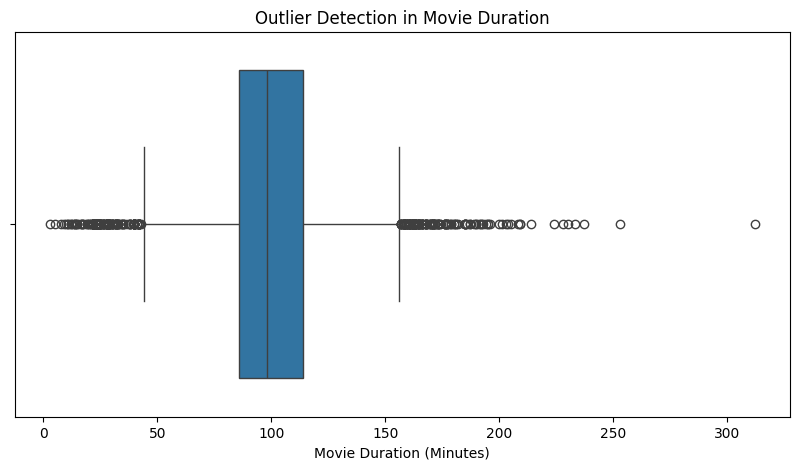

In [31]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=movie_data['movie_duration'])

plt.title('Outlier Detection in Movie Duration')

plt.xlabel('Movie Duration (Minutes)')

plt.show()

TV show season outliers

In [30]:
tv_data = df_clean[df_clean['type'] == 'TV Show']

Q1 = tv_data['seasons'].quantile(0.25)

Q3 = tv_data['seasons'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

tv_outliers = tv_data[
    (tv_data['seasons'] < lower_limit) |
    (tv_data['seasons'] > upper_limit)
]

print("Number of TV show outliers:", len(tv_outliers))

Number of TV show outliers: 231


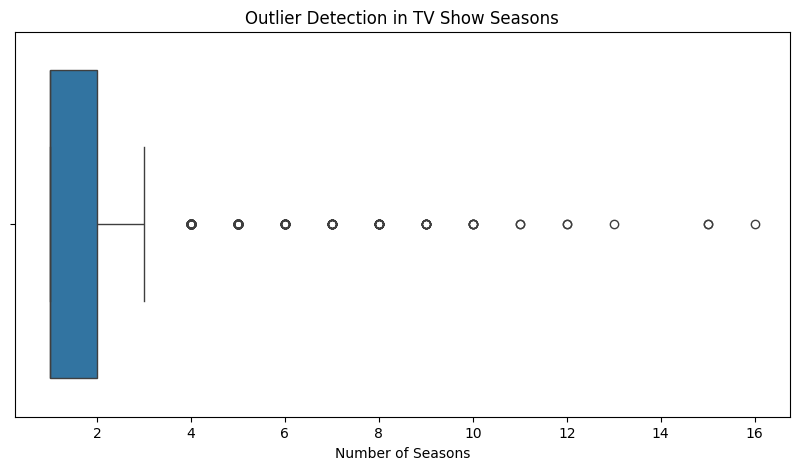

In [32]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=tv_data['seasons'])

plt.title('Outlier Detection in TV Show Seasons')

plt.xlabel('Number of Seasons')

plt.show()

**Feature Engineering**

content addition year

In [33]:
 df_clean['date_added_year'] = df_clean['date_added'].dt.year

addition month

In [34]:
df_clean['date_added_month'] = df_clean['date_added'].dt.month_name()


release decade column

In [35]:
df_clean['release_decade'] = (
    df_clean['release_year'] // 10) * 10

CHECK GARUM add vako new columns haru



In [38]:
df_clean[['date_added', 'date_added_year', 'date_added_month', 'release_decade']].head(4)

,date_added,date_added_year,date_added_month,release_decade
0,2020-08-14,2020,August,2020
1,2017-12-15,2017,December,2000
2,2019-01-05,2019,January,2010
3,2016-03-01,2016,March,2010


Aba yo cleaned dataset save garum

In [39]:
df_clean.to_csv('Netflix_Cleaned.csv', index=False)

**EDA**

**BUSINESS QUESTIONS**

- Which content type dominates Netflix?

- What is the percentage difference?

- Does Netflix have a greater variety of movies or TV shows?

**Movies vs TV Shows** IN count plot herum

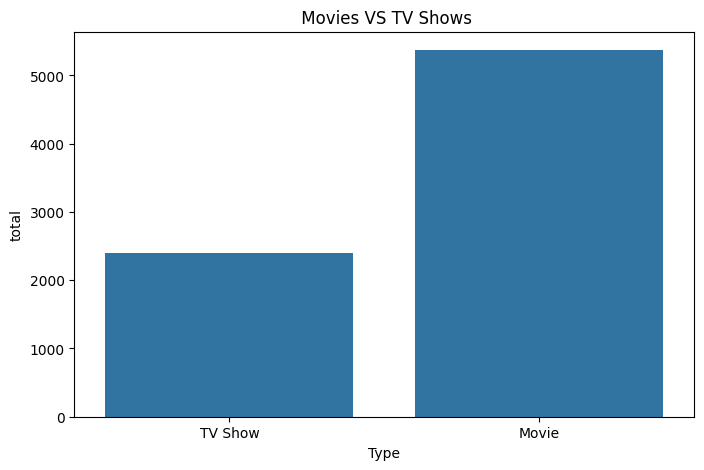

In [41]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='type'
)

plt.title(' Movies VS TV Shows')

plt.xlabel('Type')

plt.ylabel('total')

plt.show()

**Content Growth Over Time**


**Business Questions**

- During which year did Netflix add the most content?

- Was content addition increasing or decreasing?

- Did Netflix experience a sudden increase or decline?

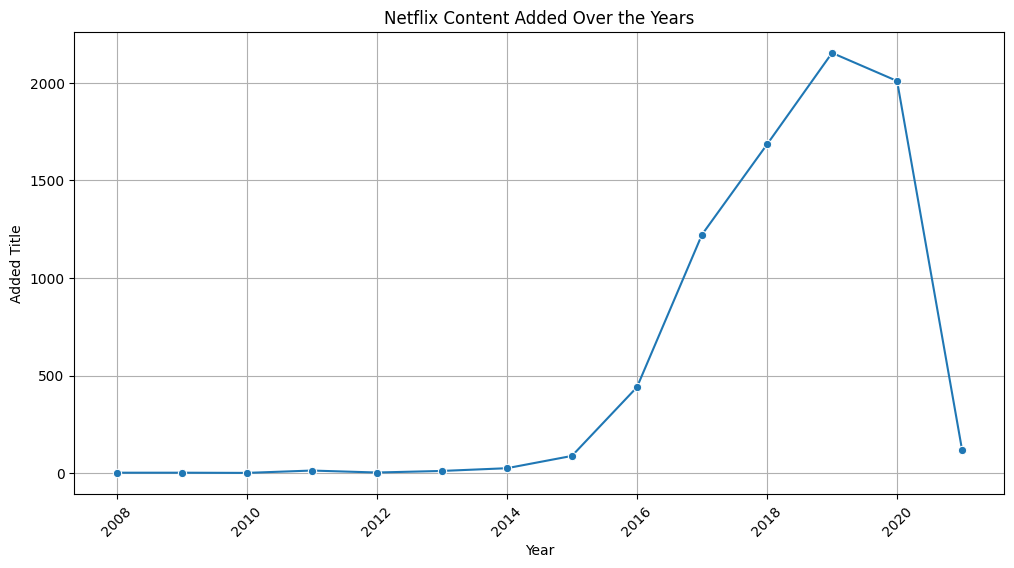

In [42]:
yearly_content = df_clean['date_added_year'].value_counts().sort_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=yearly_content.index,
    y=yearly_content.values,
    marker='o'
)

plt.title('Netflix Content Added Over the Years')

plt.xlabel('Year')

plt.ylabel('Added Title')

plt.xticks(rotation=45)

plt.grid(True)

plt.show()

In [43]:
print("Year with highest content additions:",yearly_content.idxmax())
print("Number of titles added:",yearly_content.max())

Year with highest content additions: 2019
Number of titles added: 2153


**Country Analysis**



**Business questions**

- Which country contributes the most content?

- Which countries dominate Netflix's content library?

- How significant is international content?

In [45]:
country_data = df_clean[
    df_clean['country'] != 'Not Given'].copy()

country_data['country'] = country_data['country'].str.split(',')

country_data = country_data.explode('country')

country_data['country'] = country_data['country'].str.strip()

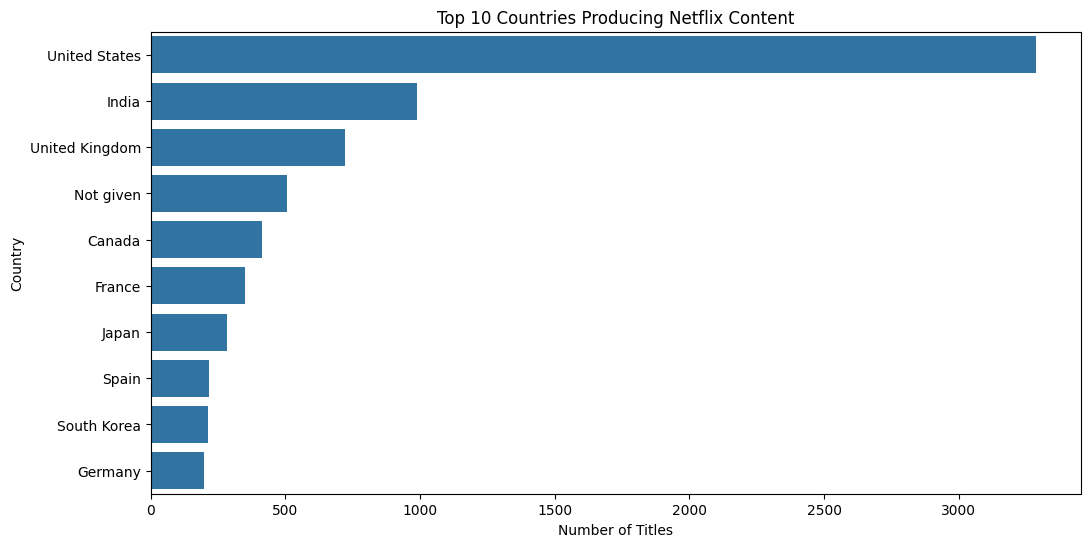

In [46]:
top_countries = country_data['country'].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title('Top 10 Countries Producing Netflix Content')

plt.xlabel('Number of Titles')

plt.ylabel('Country')

plt.show()

**Genre Analysis**


**Business questions**
1. Which genre dominates Netflix?
2. What are the most common entertainment categories?
3. Does Netflix have a stronger presence in international content, dramas or movies?

In [48]:
genre_data = df_clean.copy()

genre_data['genres'] = genre_data['genres'].str.split(',')

genre_data = genre_data.explode('genres')

genre_data['genres'] = genre_data['genres'].str.strip()

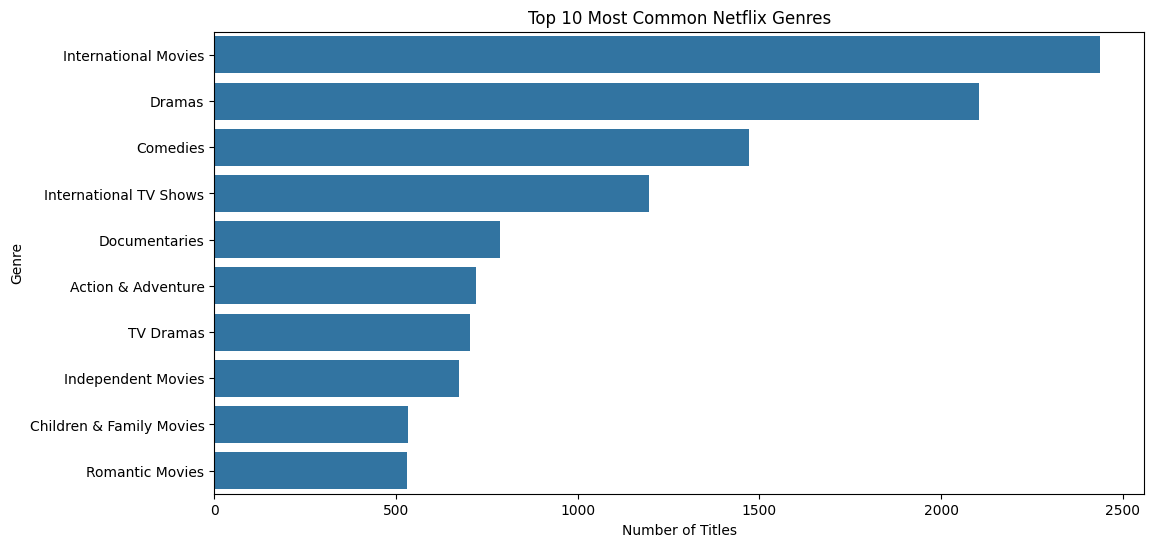

In [50]:
top_genres = genre_data['genres'].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title('Top 10 Most Common Netflix Genres')

plt.xlabel('Number of Titles')

plt.ylabel('Genre')

plt.show()

**Rating Analysis**

**Business questions**
- Which content rating is most common?
- Does Netflix have more mature-audience content?
- How is content distributed across different audience categories?

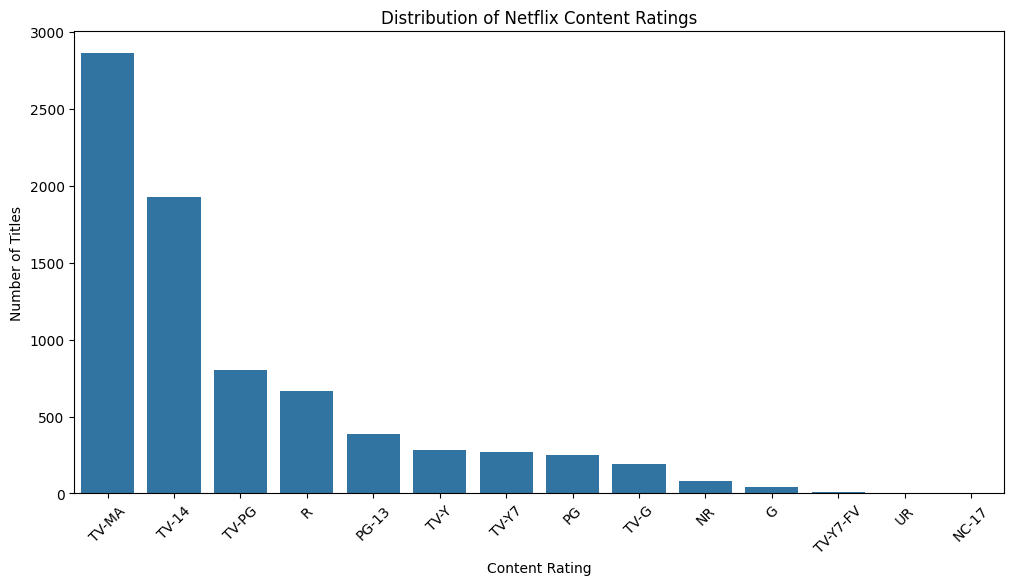

In [51]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_clean,
    x='rating',
    order=df_clean['rating'].value_counts().index
)

plt.title('Distribution of Netflix Content Ratings')

plt.xlabel('Content Rating')

plt.ylabel('Number of Titles')

plt.xticks(rotation=45)

plt.show()

In [52]:
df_clean['rating'].value_counts()

,count
rating,
TV-MA,2861
TV-14,1928
TV-PG,804
R,665
PG-13,386
TV-Y,279
TV-Y7,270
PG,247
TV-G,194


**Movie Duration Analysis**

**Business questions**

1. What is the typical movie duration?
2. Are shorter or longer movies more common?
3. Is the distribution skewed?

 ALSO:

1.  Average movie duration.
2. Median movie duration.
3. Minimum movie duration.
4. Maximum movie duration.
5. Standard deviation.


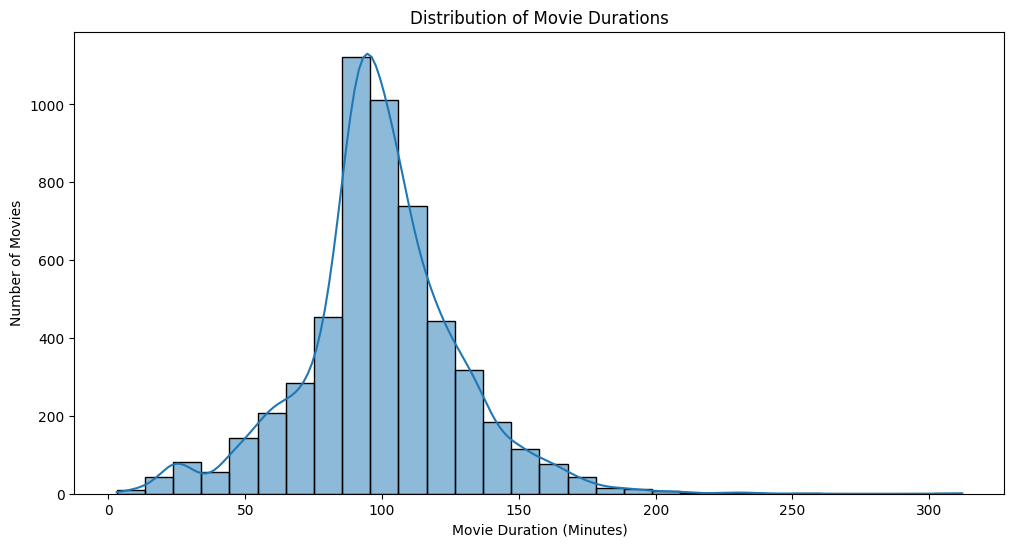

In [54]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_clean[df_clean['type'] == 'Movie'],
    x='movie_duration',
    bins=30,
    kde=True
)

plt.title('Distribution of Movie Durations')

plt.xlabel('Movie Duration (Minutes)')

plt.ylabel('Number of Movies')

plt.show()

In [53]:
df_clean[df_clean['type'] == 'Movie']['movie_duration'].describe()

,movie_duration
count,5372.000000
mean,99.330417
std,28.524206
min,3.000000
25%,86.000000
50%,98.000000
75%,114.000000
max,312.000000


**TV Show Seasons Analysis**

**Business questions**
- How many seasons do most Netflix shows have?
- Are limited-season shows more common?
- How many shows have a long-running format?

In [55]:
df_clean[df_clean['type'] == 'TV Show']['seasons'].describe()

,seasons
count,2398.000000
mean,1.761468
std,1.561099
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,16.000000


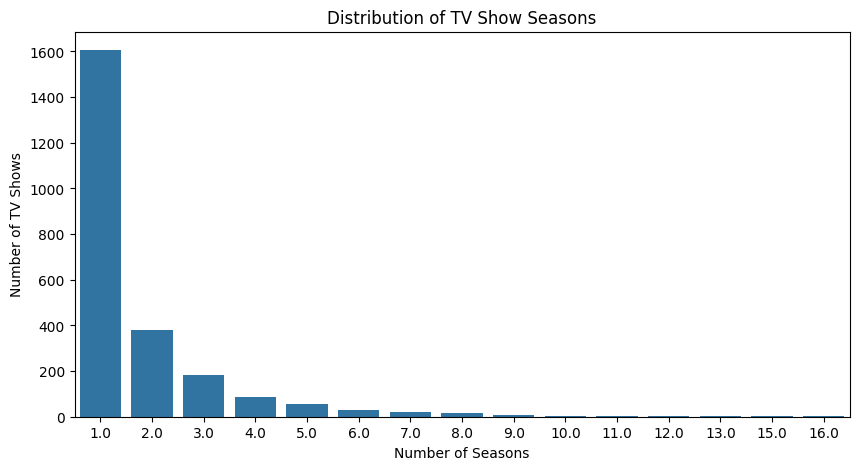

In [56]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean[df_clean['type'] == 'TV Show'],
    x='seasons',
    order=sorted(
        df_clean[df_clean['type'] == 'TV Show']['seasons'].dropna().unique()
    )
)

plt.title('Distribution of TV Show Seasons')

plt.xlabel('Number of Seasons')

plt.ylabel('Number of TV Shows')

plt.show()

**Release Year Analysis**

**Business questions**
- Which decade contributes the most titles?
- Does Netflix mainly feature recent content?
- How much older content is available?

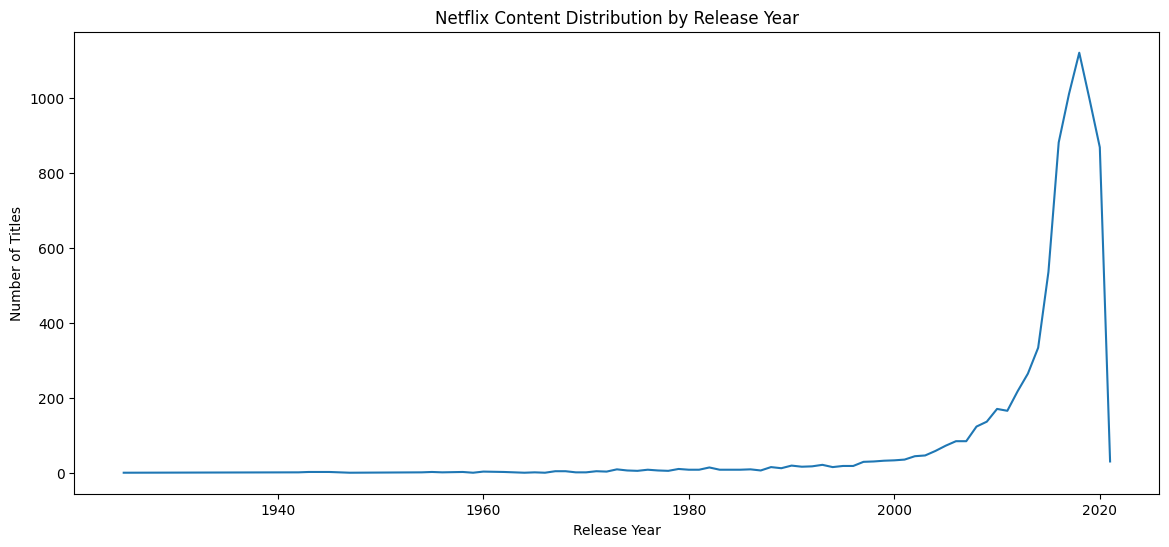

In [58]:
release_year_counts = df_clean['release_year'].value_counts().sort_index()

plt.figure(figsize=(14, 6))

sns.lineplot(
    x=release_year_counts.index,
    y=release_year_counts.values
)

plt.title('Netflix Content Distribution by Release Year')

plt.xlabel('Release Year')

plt.ylabel('Number of Titles')

plt.show()

Decade wise ni herum

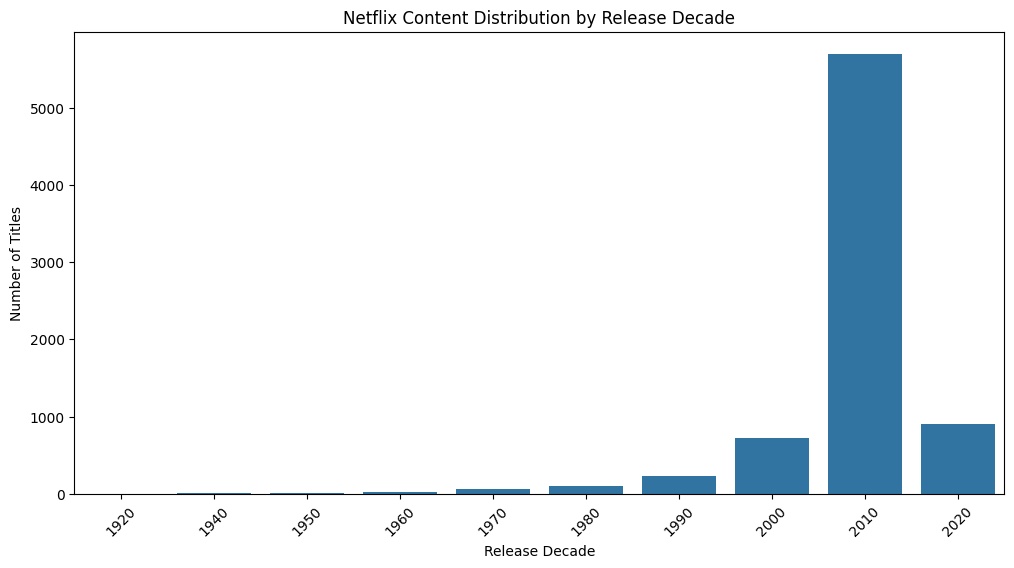

In [57]:
decade_counts = df_clean['release_decade'].value_counts().sort_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=decade_counts.index.astype(str),
    y=decade_counts.values
)

plt.title('Netflix Content Distribution by Release Decade')

plt.xlabel('Release Decade')

plt.ylabel('Number of Titles')

plt.xticks(rotation=45)

plt.show()

**Monthly Content Additions**

**Business questions**
- Which month has the highest content additions?
- Which month has the lowest?
- Are there noticeable seasonal patterns?

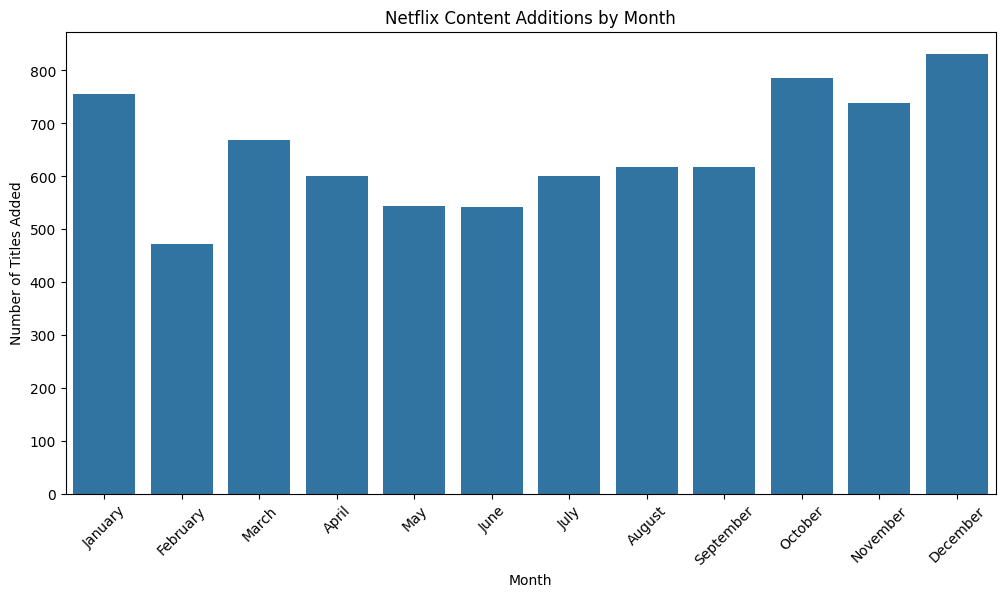

In [59]:
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_content = df_clean['date_added_month'].value_counts()

monthly_content = monthly_content.reindex(month_order)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=monthly_content.index,
    y=monthly_content.values
)

plt.title('Netflix Content Additions by Month')

plt.xlabel('Month')

plt.ylabel('Number of Titles Added')

plt.xticks(rotation=45)

plt.show()

**Relationship and co-relation Analysis**

Content Type and Rating ko herum hai ta first


**Business questions**
- Which ratings are more common among movies?
- Which ratings are more common among TV shows?
- Are there noticeable differences in content classification?

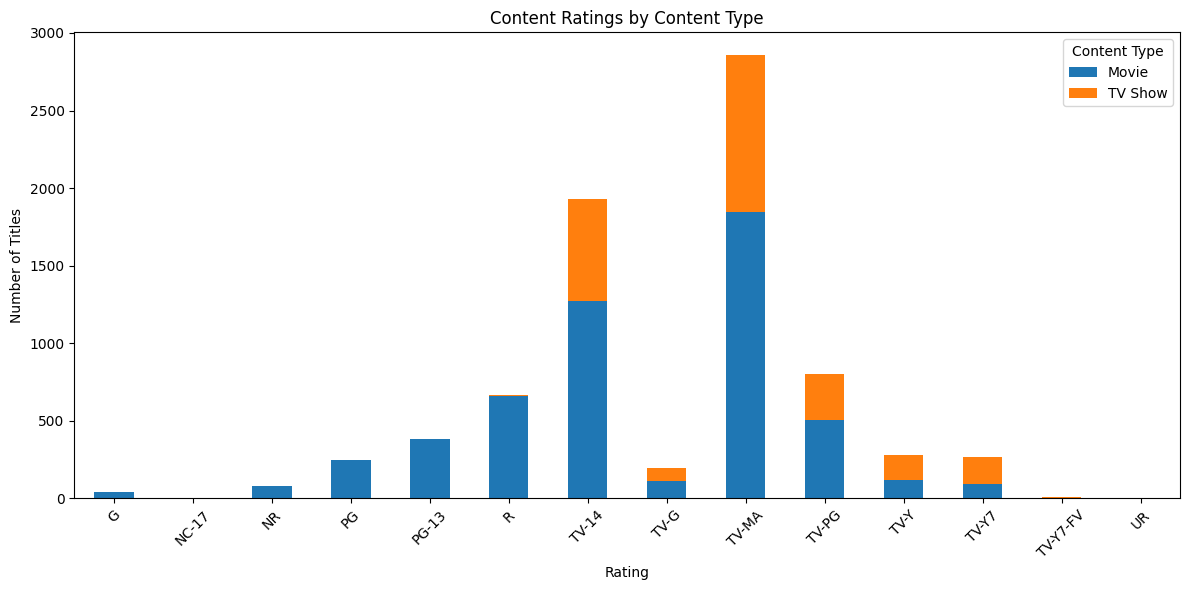

In [60]:
rating_type = pd.crosstab(
    df_clean['rating'],
    df_clean['type']
)

rating_type.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Content Ratings by Content Type')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.legend(title='Content Type')
plt.tight_layout()
plt.show()

**Movie** **correlation**

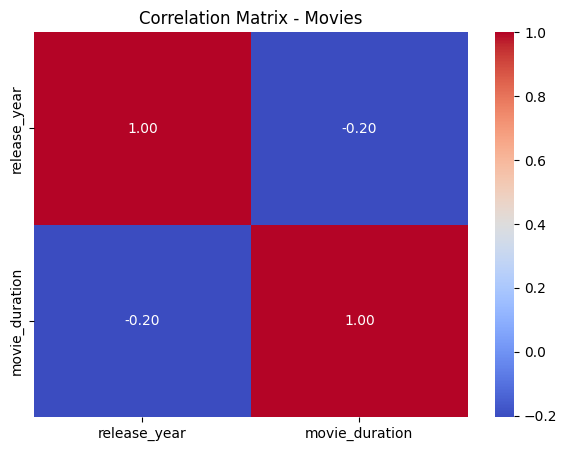

In [61]:
movie_corr = df_clean[
    df_clean['type'] == 'Movie'
][['release_year', 'movie_duration']]

correlation_movie = movie_corr.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_movie,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix - Movies')

plt.show()

**TV show co-relation**

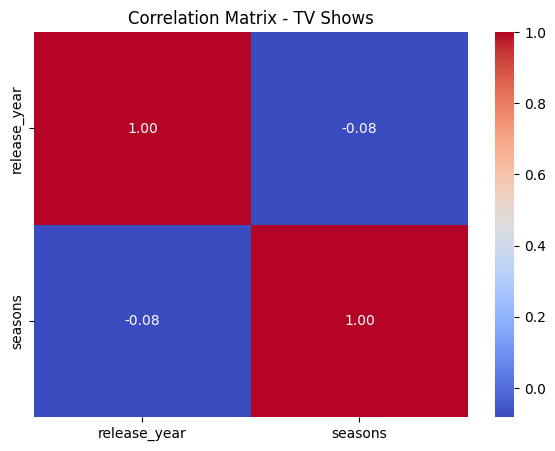

In [63]:
tv_corr = df_clean[
    df_clean['type'] == 'TV Show'
][['release_year', 'seasons']]

correlation_tv = tv_corr.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_tv,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix - TV Shows')

plt.show()

**overall corelation **

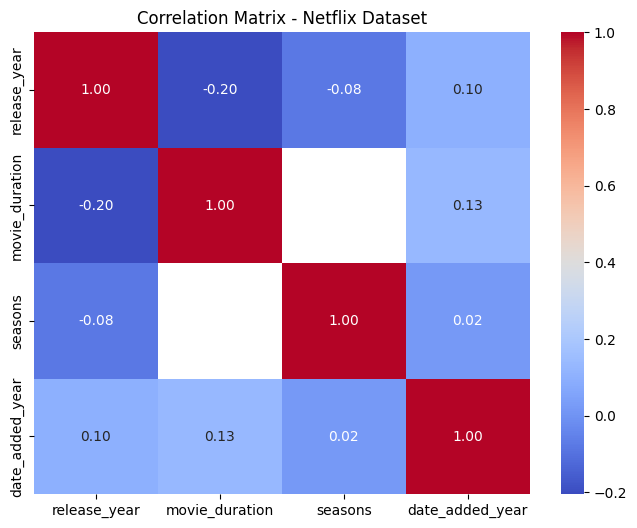

In [62]:
numeric_df = df_clean[
    ['release_year', 'movie_duration', 'seasons', 'date_added_year']
]

correlation = numeric_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix - Netflix Dataset')

plt.show()

# 7. Key Insights and Findings

The exploratory data analysis of the Netflix dataset revealed several important patterns and trends regarding content distribution, geographical representation, genres, ratings, release years and content duration.

### 7.1 Movie and TV Show Distribution

The cleaned dataset contains 7,770 records, consisting of:

- Movies: 5,372 (69.1%)
- TV Shows: 2,398 (30.9%)

**Insight:** Movies represent approximately 69% of the dataset, indicating that the Netflix content library contains considerably more movie titles than television shows.

### 7.2 Content Added Over Time

The analysis of content addition dates revealed that:

- 2019 had the highest number of content additions, with 2,153 titles.
- 2020 followed with 2,009 titles.
- 2018 recorded 1,684 additions.

**Insight:** Content additions increased significantly between 2016 and 2019. However, the number of additions decreased in 2020 and 2021. This suggests that the dataset records different levels of content addition across the years.

### 7.3 Geographical Content Distribution

The country analysis identified the following leading countries:

1. United States: 3,288 country-title associations.
2. India: 990.
3. United Kingdom: 722.
4. Canada: 412.
5. France: 349.

**Insight:** The United States has the highest representation in the dataset, followed by India and the United Kingdom. This demonstrates the strong geographical representation of these countries in the available Netflix content.

*Note: Some titles are associated with multiple countries, so these figures represent country-title associations rather than exclusive title counts.*

### 7.4 Genre Distribution

The most frequently appearing genres were:

- International Movies: 2,437
- Dramas: 2,105
- Comedies: 1,471
- International TV Shows: 1,197
- Documentaries: 786

**Insight:** International Movies, Dramas and Comedies are among the most frequently represented categories. This indicates a broad content offering across international entertainment, drama and comedy.

*Note: Individual titles can belong to multiple genres.*

### 7.5 Content Rating Distribution

The most common content ratings were:

- TV-MA: 2,861 titles.
- TV-14: 1,928 titles.
- TV-PG: 804 titles.
- R: 665 titles.
- PG-13: 386 titles.

**Insight:** TV-MA is the most frequently appearing rating, followed by TV-14. This indicates that mature-audience and teenage-audience classifications account for a substantial proportion of the dataset.

### 7.6 Movie Duration Analysis

The movie duration analysis produced the following results:

- Average movie duration: approximately 99.33 minutes.
- Median movie duration: 98 minutes.
- Shortest recorded duration: 3 minutes.
- Longest recorded duration: 312 minutes.

**Insight:** The average and median movie durations are relatively close, suggesting that a typical movie in this dataset has a duration of approximately 98–99 minutes. However, the dataset also contains some unusually short and long titles.

### 7.7 TV Show Seasons Analysis

The TV Show analysis revealed:

- 1,606 TV Shows have one season.
- 378 TV Shows have two seasons.
- 183 TV Shows have three seasons.

Approximately 67% of the TV Shows in the cleaned dataset have only one season.

**Insight:** Single-season programmes dominate the TV Show category. This indicates that the dataset contains considerably more one-season titles than long-running multi-season programmes.

### 7.8 Release Year Analysis

The release-year analysis identified the following years with the highest numbers of titles:

- 2018: 1,120 titles.
- 2017: 1,010 titles.
- 2019: 996 titles.
- 2016: 881 titles.
- 2020: 868 titles.

The 2010s were the most represented release decade, accounting for approximately 73.3% of the cleaned dataset.

**Insight:** Netflix's available content in this dataset is strongly represented by titles released during the 2010s, although older titles are also included.

### 7.9 Monthly Content Addition Analysis

The monthly analysis showed that:

- December recorded the highest number of additions, with 832 titles.
- October followed with 785 titles.
- January recorded 756 titles.

**Insight:** December had the highest number of content additions in the dataset. However, this pattern should not automatically be interpreted as a recurring seasonal trend because the dataset covers an unequal number of observations across years.

### 7.10 Movie Correlation Analysis

The Pearson correlation between movie release year and movie duration was approximately:

**-0.205**

**Insight:** The result indicates a weak negative linear relationship between movie release year and duration. In this dataset, newer release years are slightly associated with shorter movie durations, but the relationship is weak and does not establish causation.

### 7.11 TV Show Correlation Analysis

The Pearson correlation between TV Show release year and number of seasons was approximately:

**-0.082**

**Insight:** The result indicates a very weak negative linear relationship between release year and the number of seasons. There is little evidence of a meaningful linear relationship between these two variables in this dataset.

### 7.12 Overall Findings

The analysis demonstrates that:

1. Movies account for the majority of titles in the dataset.
2. The United States is the most frequently represented country.
3. International Movies, Dramas and Comedies are among the leading genre categories.
4. TV-MA is the most common content rating.
5. The typical movie duration is approximately 98–99 minutes.
6. Most TV Shows have only one season.
7. Titles released during the 2010s dominate the dataset.
8. December has the highest number of recorded content additions.
9. Movie duration has a weak negative correlation with release year.
10. TV Show seasons have a very weak negative correlation with release year.

Overall, the findings provide a clearer understanding of Netflix's content composition, geographical distribution, genre diversity and historical release patterns.

